# Del 1: Grundläggande analys och statistik

## Introduktion
Denna analys syftar till att genomföra en grundläggande explorativ dataanalys (EDA) på ett hälsorelaterat dataset (`health_study_dataset.csv`). Målet är att utforska fördelningen av olika hälsomarkörer, identifiera mönster samt undersöka samband mellan livsstils- och biometriska faktorer och förekomsten av sjukdom.

## Datauppsättning & Kolumnbeskrivning
Datasetet innehåller hälsodata för en grupp individer. Nedan följer en beskrivning av datasetets kolumner:

* **`id`**: Unikt identifieringsnummer för varje deltagare.
* **`age`**: Deltagarens ålder (år).
* **`sex`**: Biologiskt kön (`M` = Man, `F` = Kvinna).
* **`height`**: Längd i centimeter (cm).
* **`weight`**: Vikt i kilogram (kg).
* **`systolic_bp`**: Systoliskt blodtryck (mmHg).
* **`cholesterol`**: Kolesterolhalt i blodet (mmol/L).
* **`smoker`**: Rökstatus (`Yes` = Rökare, `No` = Icke-rökare).
* **`disease`**: Förekomst av diagnostiserad sjukdom (`0` = Nej/Frisk, `1` = Ja/Sjukdom).

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.dpi"] = 120
np.set_printoptions(precision=3)
pd.set_option("display.precision", 3)

np.random.seed(42)



In [7]:
df = pd.read_csv("../data/health_study_dataset.csv")

print(df.head())
print()
display(df.info())
print(df.describe())


   id  age sex  height  weight  systolic_bp  cholesterol smoker  disease
0   1   57   F   168.9    65.8        141.8         4.58     No        0
1   2   47   M   180.4    95.9        144.8         5.18    Yes        0
2   3   59   F   169.9    82.2        151.7         6.16     No        0
3   4   72   M   157.7    93.1        151.0         6.63     No        0
4   5   46   M   192.6   104.1        144.1         5.21     No        0

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes

None

            id      age   height   weight  systolic_bp  cholesterol  disease
count  800.000  800.000  800.000  800.000      800.000      800.000  800.000
mean   400.500   49.426  171.849   73.413      149.179        4.929    0.059
std    231.084   14.501    9.804   13.685       12.793        0.848    0.235
min      1.000   18.000  144.400   33.700      106.800        2.500    0.000
25%    200.750   39.000  164.775   64.800      140.900        4.328    0.000
50%    400.500   50.000  171.350   73.200      149.400        4.970    0.000
75%    600.250   59.000  178.925   82.600      157.600        5.482    0.000
max    800.000   90.000  200.400  114.400      185.900        7.880    1.000


In [8]:
print(df.isna().sum())          # number of missing values per column
print()
dup_mask = df.duplicated(keep=False)
print("Antal dubletter:", dup_mask.sum())
print()
print(df["sex"].value_counts())
print(df["smoker"].value_counts())  # check that there are only the expected values (M/F, Yes/No)


id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Antal dubletter: 0

sex
F    403
M    397
Name: count, dtype: int64
smoker
No     587
Yes    213
Name: count, dtype: int64


OBS: Filen (9 kolumner och 800 rader) ser välordnad/rent ut; det finns inga saknade data eller dubbletter. Även datatyperna verkar rimliga.

In [9]:
# Beskrivande analys:

cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]
print("- Räkning av medel, median, min och max för: age, weight, height, systolic_bp, cholesterol:\n")
display(df[cols].agg(["mean", "median", "min", "max"]).round(2))


- Räkning av medel, median, min och max för: age, weight, height, systolic_bp, cholesterol:



,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


### Några observationer kring tabellen ovan:
- Medelvärdet och medianen ligger mycket nära varandra för alla fem variabler, vilket tyder på symmetriska fördelningar.

- Minsta värdet för vikt är 33,7 kg, vilket är mycket lågt för en vuxen!! Är detta ett rimligt värde eller ett datafel?!

- Det genomsnittliga systoliska blodtrycket ligger på cirka 149 mmHg, vilket är ganska högt!!.


- Skapa minst 3 olika grafer (t.ex. histogram över blodtryck, boxplot över vikt per kön, stapeldiagram över andelen rökare):


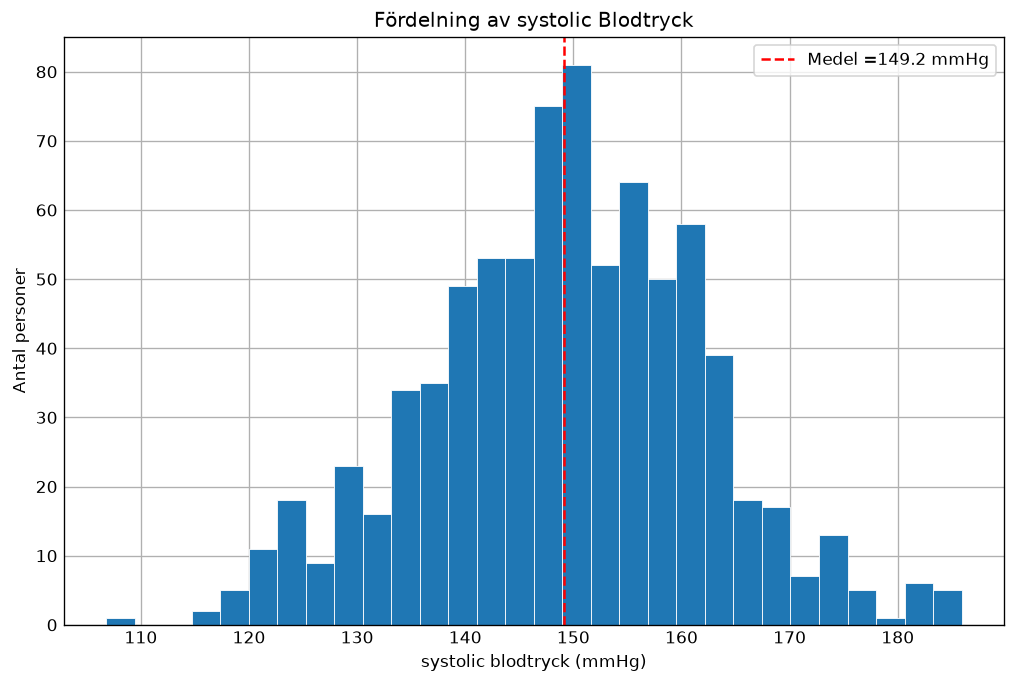

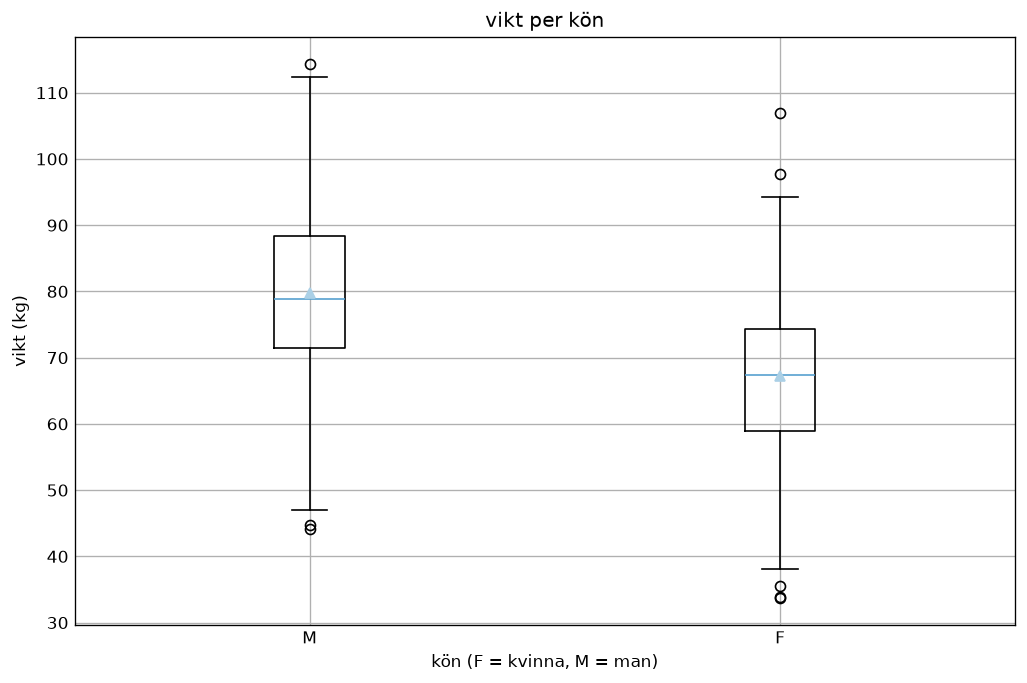

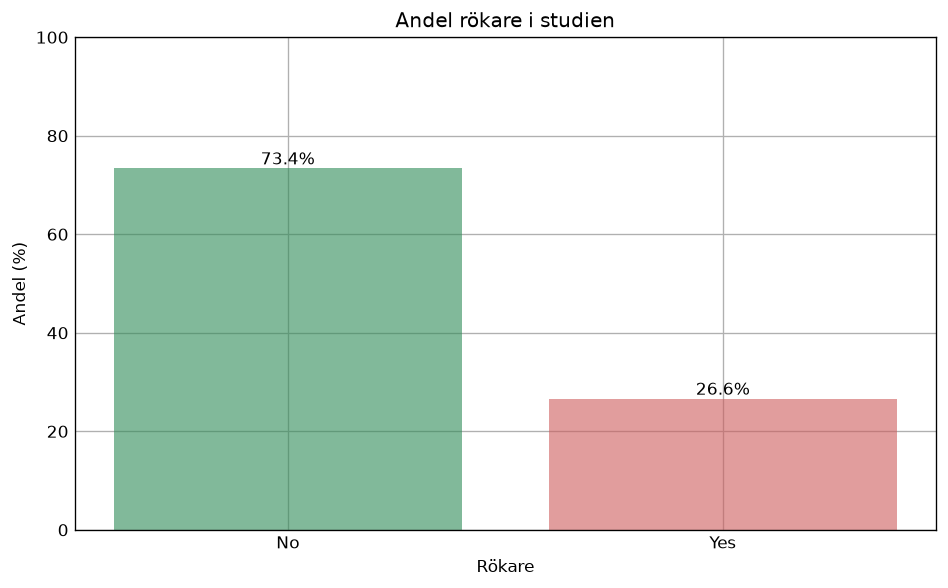

In [27]:
print("\n- Skapa minst 3 olika grafer (t.ex. histogram över blodtryck, boxplot över vikt per kön, stapeldiagram över andelen rökare):")

# graf 1: histogram över blodtryck
fig, ax = plt.subplots()
ax.hist(df["systolic_bp"], bins=30, linewidth=0.5, edgecolor="white")
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label=f"Medel ={df["systolic_bp"].mean():.1f} mmHg")
ax.set_title("Fördelning av systolic Blodtryck")
ax.set_xlabel("systolic blodtryck (mmHg)")
ax.set_ylabel("Antal personer")
ax.legend()
plt.show()

# graf 2: boxplot över vikt per kön
fig, ax = plt.subplots()
ax.boxplot([df.loc[df.sex == "M", "weight"], df.loc[df.sex == "F", "weight"]], tick_labels=["M", "F"], showmeans=True)
ax.set_title("vikt per kön")
ax.set_xlabel("kön (F = kvinna, M = man)")
ax.set_ylabel("vikt (kg)")
plt.show()

# graf 3:  stapeldiagram över andelen rökare
smoker_share = df["smoker"].value_counts(normalize=True) * 100
fig, ax = plt.subplots()
bars = ax.bar(smoker_share.index, smoker_share.values, alpha=0.6, color=["seagreen", "indianred"])
ax.bar_label(bars, fmt="%.1f%%")
ax.set_title("Andel rökare i studien")
ax.set_xlabel("Rökare")
ax.set_ylabel("Andel (%)")
ax.grid(True, axis="y")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()
